In [2]:
import pandas as pd

orders = pd.read_csv("../data/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

orders["delay_days"] = (orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]).dt.days

orders[["order_id", "delay_days"]].head()

,order_id,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0


In [4]:
print("Toplam sipariş:", len(orders))
print("delay_days boş olan:", orders["delay_days"].isna().sum())
print("Geciken sipariş (delay_days > 0):", (orders["delay_days"] > 0).sum())
orders["order_status"].value_counts()

Toplam sipariş: 99441
delay_days boş olan: 2965
Geciken sipariş (delay_days > 0): 6535


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [5]:
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")
print(reviews.shape)
reviews[["order_id", "review_score"]].head()

(99224, 7)


,order_id,review_score
0,73fc7af87114b39712e6da79b0a377eb,4
1,a548910a1c6147796b98fdf73dbeba33,5
2,f9e4b658b201a9f2ecdecbb34bed034b,5
3,658677c97b385a9be170737859d3511b,5
4,8e6bfb81e283fa7e4f11123a3fb894f1,5


In [6]:
print(reviews["review_score"].value_counts().sort_index())
print("Benzersiz order_id:", reviews["order_id"].nunique())
print("Tekrar eden order_id satırı:", reviews["order_id"].duplicated().sum())

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Benzersiz order_id: 98673
Tekrar eden order_id satırı: 551


In [7]:
dups = reviews[reviews["order_id"].duplicated(keep=False)].sort_values("order_id")
dups[["order_id", "review_score", "review_creation_date"]].head(10)

,order_id,review_score,review_creation_date
25612,0035246a40f520710769010f752e7507,5,2017-08-29 00:00:00
22423,0035246a40f520710769010f752e7507,5,2017-08-25 00:00:00
22779,013056cfe49763c6f66bda03396c5ee3,5,2018-02-22 00:00:00
68633,013056cfe49763c6f66bda03396c5ee3,4,2018-03-04 00:00:00
854,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00
83224,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00
17582,02355020fd0a40a0d56df9f6ff060413,1,2018-03-29 00:00:00
89888,02355020fd0a40a0d56df9f6ff060413,3,2018-03-21 00:00:00
55137,029863af4b968de1e5d6a82782e662f5,4,2017-07-19 00:00:00
37911,029863af4b968de1e5d6a82782e662f5,5,2017-07-14 00:00:00


In [8]:
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])

reviews_clean = (
    reviews.sort_values("review_creation_date")
           .drop_duplicates(subset="order_id", keep="last")
)

print(reviews_clean.shape)
print("Tekrar eden order_id:", reviews_clean["order_id"].duplicated().sum())

(98673, 7)
Tekrar eden order_id: 0


In [9]:
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["delay_days"])

df = delivered.merge(
    reviews_clean[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

print("Teslim edilen sipariş:", len(delivered))
print("Birleştirme sonrası:", df.shape)
df[["order_id", "delay_days", "review_score"]].head()

Teslim edilen sipariş: 96470
Birleştirme sonrası: (95824, 10)


,order_id,delay_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0,4
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0,4
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0,5
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0,5
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0,5


In [10]:
df["is_late"] = df["delay_days"] > 0

df.groupby("is_late")["review_score"].agg(["count", "mean", "median"])

,count,mean,median
is_late,,,
False,89443,4.290274,5.0
True,6381,2.270804,1.0


In [11]:
pd.crosstab(df["is_late"], df["review_score"], normalize="index").round(3) * 100

review_score,1,2,3,4,5
is_late,,,,,
False,6.6,2.6,8.1,20.4,62.3
True,53.8,8.6,10.9,10.2,16.5


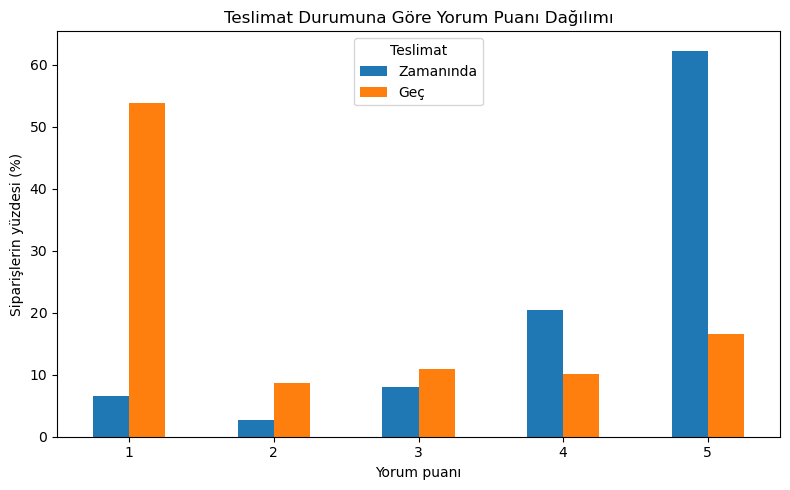

In [12]:
import matplotlib.pyplot as plt

dist = pd.crosstab(df["is_late"], df["review_score"], normalize="index") * 100
dist.index = ["Zamanında", "Geç"]

dist.T.plot(kind="bar", figsize=(8, 5))
plt.title("Teslimat Durumuna Göre Yorum Puanı Dağılımı")
plt.xlabel("Yorum puanı")
plt.ylabel("Siparişlerin yüzdesi (%)")
plt.xticks(rotation=0)
plt.legend(title="Teslimat")
plt.tight_layout()
plt.savefig("../images/score_distribution.png", dpi=150)
plt.show()

In [13]:
from scipy.stats import mannwhitneyu

on_time = df.loc[~df["is_late"], "review_score"]
late = df.loc[df["is_late"], "review_score"]

stat, p = mannwhitneyu(late, on_time, alternative="two-sided")
print("U istatistiği:", stat)
print("p-değeri:", p)

U istatistiği: 103363826.0
p-değeri: 0.0


In [14]:
n_late = len(late)
n_on_time = len(on_time)

prob = stat / (n_late * n_on_time)
rank_biserial = 2 * prob - 1

print("Olasılık (geç > zamanında):", round(prob, 3))
print("Rank-biserial korelasyon:", round(rank_biserial, 3))

Olasılık (geç > zamanında): 0.181
Rank-biserial korelasyon: -0.638


In [15]:
late_df = df[df["delay_days"] > 0].copy()

late_df["delay_group"] = pd.cut(
    late_df["delay_days"],
    bins=[0, 3, 7, 14, float("inf")],
    labels=["1-3 gün", "4-7 gün", "8-14 gün", "15+ gün"]
)

late_df.groupby("delay_group", observed=True)["review_score"].agg(["count", "mean"])

,count,mean
delay_group,,
1-3 gün,1852,3.291037
4-7 gün,1748,2.104691
8-14 gün,1446,1.670816
15+ gün,1335,1.722846


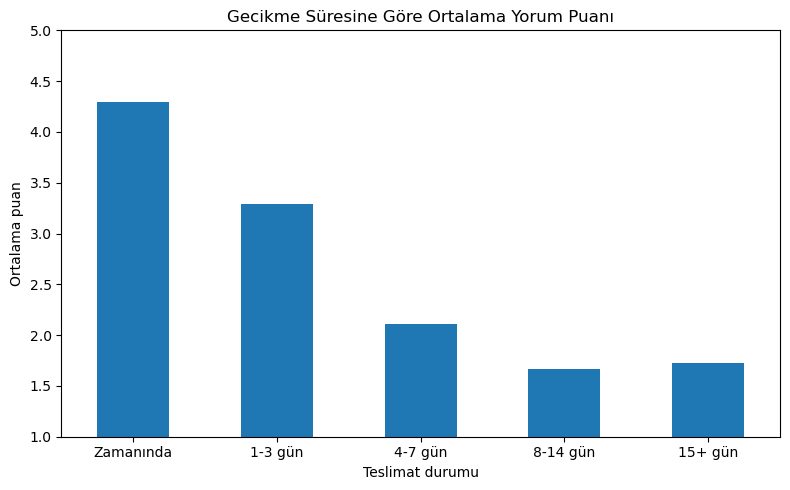

In [16]:
summary = late_df.groupby("delay_group", observed=True)["review_score"].mean()
on_time_mean = df.loc[~df["is_late"], "review_score"].mean()

summary = pd.concat([pd.Series({"Zamanında": on_time_mean}), summary])

summary.plot(kind="bar", figsize=(8, 5))
plt.title("Gecikme Süresine Göre Ortalama Yorum Puanı")
plt.xlabel("Teslimat durumu")
plt.ylabel("Ortalama puan")
plt.xticks(rotation=0)
plt.ylim(1, 5)
plt.tight_layout()
plt.savefig("../images/delay_vs_score.png", dpi=150)
plt.show()